In [1]:
import pandas as pd 
import matplotlib.pyplot as plt

In [2]:
from pathlib import Path

csv_path = Path(r"csv\student_attendance.csv")
if not csv_path.exists():
    csv_path = Path(r"..\csv\student_attendance.csv")

df = pd.read_csv(csv_path)

In [3]:
performance_df=pd.read_csv(r'..\csv/student_performance.csv')

In [4]:
df.shape

(23, 4)

In [5]:
performance_df.shape

(22, 2)

In [6]:
before=df.shape[0]

In [7]:
df.duplicated().sum()

np.int64(1)

In [8]:
df.drop_duplicates(inplace=True)

In [9]:
after=df.shape[0]

In [10]:
after

22

In [11]:
deleted=before-after
print("duplicate are ",deleted)

duplicate are  1


In [12]:
df.isna().sum()

Student_ID               0
Department               0
Attendance_Percentage    1
Classes_Attended         1
dtype: int64

In [13]:
df.fillna({'Attendance_Percentage':df['Attendance_Percentage'].mean(),'Classes_Attended':df['Classes_Attended'].mean()},inplace=True)

,Student_ID,Department,Attendance_Percentage,Classes_Attended
0,S101,Computer Science,92.000000,18.000000
1,S102,Mathematics,85.000000,20.000000
2,S103,Computer Science,78.000000,15.000000
3,S104,Physics,96.000000,22.000000
4,S105,Computer Science,88.000000,19.000000
5,S106,Biology,73.000000,12.000000
6,S107,Mathematics,90.000000,21.000000
7,S108,Physics,81.000000,16.000000
8,S109,Biology,87.000000,18.000000
9,S110,Computer Science,69.000000,10.000000


In [14]:
merged=df.merge(performance_df,on='Student_ID',how='inner')

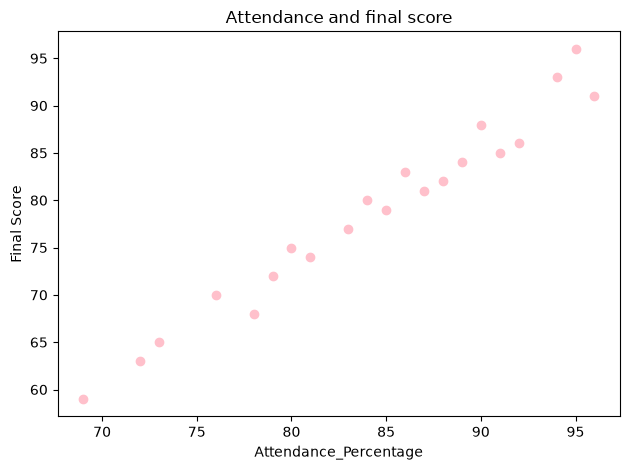

In [15]:
plt.scatter(merged['Attendance_Percentage'],merged['Final_Score'],marker='o',color='pink')
plt.xlabel("Attendance_Percentage")
plt.ylabel("Final Score")
plt.title("Attendance and final score")
plt.tight_layout()

Text(0.5, 0.98, '')

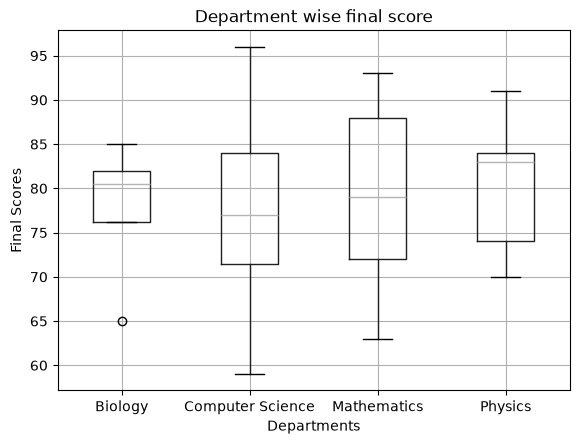

In [16]:
merged.boxplot('Final_Score',by='Department')
plt.xlabel("Departments")
plt.ylabel("Final Scores")
plt.title("Department wise final score")
plt.suptitle('')

In [17]:
import sqlite3

In [18]:
conn=sqlite3.connect('StudentPerformance.db')

In [19]:
cursor=conn.cursor()

In [20]:
merged.to_sql('StudentRecords',
              con=conn,
              if_exists='replace',
              index=False)

22

In [21]:
cursor.execute("select * from StudentRecords")

In [22]:
cursor.fetchall()

[('S101', 'Computer Science', 92.0, 18.0, 86.0),
 ('S102', 'Mathematics', 85.0, 20.0, 79.0),
 ('S103', 'Computer Science', 78.0, 15.0, 68.0),
 ('S104', 'Physics', 96.0, 22.0, 91.0),
 ('S105', 'Computer Science', 88.0, 19.0, 82.0),
 ('S106', 'Biology', 73.0, 12.0, 65.0),
 ('S107', 'Mathematics', 90.0, 21.0, 88.0),
 ('S108', 'Physics', 81.0, 16.0, 74.0),
 ('S109', 'Biology', 87.0, 18.0, 81.0),
 ('S110', 'Computer Science', 69.0, 10.0, 59.0),
 ('S111', 'Mathematics', 94.0, 23.0, 93.0),
 ('S112', 'Physics', 76.0, 14.0, 70.0),
 ('S113', 'Biology', 91.0, 20.0, 85.0),
 ('S114', 'Computer Science', 83.0, 17.0, 77.0),
 ('S115', 'Mathematics', 79.0, 15.0, 72.0),
 ('S116', 'Physics', 89.0, 19.0, 84.0),
 ('S117', 'Biology', 84.0, 16.0, 80.0),
 ('S118', 'Computer Science', 95.0, 24.0, 96.0),
 ('S119', 'Mathematics', 72.0, 11.0, 63.0),
 ('S120', 'Physics', 86.0, 18.0, 83.0),
 ('S121', 'Biology', 84.19047619047619, 17.0, None),
 ('S122', 'Computer Science', 80.0, 17.38095238095238, 75.0)]

In [23]:
cursor.execute("select count(*) from studentRecords")

In [24]:
cursor.fetchall()

[(22,)]

In [25]:
department='Computer Science'
cursor.execute("select * from studentRecords where Department=?",(department,))

In [26]:
cursor.fetchall()

[('S101', 'Computer Science', 92.0, 18.0, 86.0),
 ('S103', 'Computer Science', 78.0, 15.0, 68.0),
 ('S105', 'Computer Science', 88.0, 19.0, 82.0),
 ('S110', 'Computer Science', 69.0, 10.0, 59.0),
 ('S114', 'Computer Science', 83.0, 17.0, 77.0),
 ('S118', 'Computer Science', 95.0, 24.0, 96.0),
 ('S122', 'Computer Science', 80.0, 17.38095238095238, 75.0)]

In [27]:
cursor.execute('update studentRecords set Final_Score=? where Student_ID=?',('S104',88,))

In [28]:
cursor.execute("select * from studentRecords")

In [29]:
cursor.fetchall()

[('S101', 'Computer Science', 92.0, 18.0, 86.0),
 ('S102', 'Mathematics', 85.0, 20.0, 79.0),
 ('S103', 'Computer Science', 78.0, 15.0, 68.0),
 ('S104', 'Physics', 96.0, 22.0, 91.0),
 ('S105', 'Computer Science', 88.0, 19.0, 82.0),
 ('S106', 'Biology', 73.0, 12.0, 65.0),
 ('S107', 'Mathematics', 90.0, 21.0, 88.0),
 ('S108', 'Physics', 81.0, 16.0, 74.0),
 ('S109', 'Biology', 87.0, 18.0, 81.0),
 ('S110', 'Computer Science', 69.0, 10.0, 59.0),
 ('S111', 'Mathematics', 94.0, 23.0, 93.0),
 ('S112', 'Physics', 76.0, 14.0, 70.0),
 ('S113', 'Biology', 91.0, 20.0, 85.0),
 ('S114', 'Computer Science', 83.0, 17.0, 77.0),
 ('S115', 'Mathematics', 79.0, 15.0, 72.0),
 ('S116', 'Physics', 89.0, 19.0, 84.0),
 ('S117', 'Biology', 84.0, 16.0, 80.0),
 ('S118', 'Computer Science', 95.0, 24.0, 96.0),
 ('S119', 'Mathematics', 72.0, 11.0, 63.0),
 ('S120', 'Physics', 86.0, 18.0, 83.0),
 ('S121', 'Biology', 84.19047619047619, 17.0, None),
 ('S122', 'Computer Science', 80.0, 17.38095238095238, 75.0)]

In [30]:
conn.commit()

In [31]:
df2=pd.read_sql_query("""select Student_ID,Department,Final_Score from studentRecords where Final_Score>=75 order by Final_Score DESC""",con=conn)

In [32]:
df2.head()

,Student_ID,Department,Final_Score
0,S118,Computer Science,96.0
1,S111,Mathematics,93.0
2,S104,Physics,91.0
3,S107,Mathematics,88.0
4,S101,Computer Science,86.0


In [33]:
# %pip install --force-reinstall torch

In [34]:
import torch

In [39]:
x=torch.randn(150,5)

In [41]:
w=torch.randn(5,1)

In [42]:
noise=torch.randn(150,1)*0.1

In [43]:
y=x@w+3+noise

In [45]:
y.shape

torch.Size([150, 1])

In [48]:
import torch.nn as nn
import torch.optim as optim

In [52]:
class StudentNet(nn.Module):

    def __init__(self):
        super(StudentNet,self).__init__()
        self.network=nn.Sequential(
                        nn.Linear(5,12),
                        nn.ReLU(),
                        nn.Linear(12,6),
                        nn.ReLU(),
                        nn.Linear(6,1))

    def forward(self,x):
        return self.network(x)

model=StudentNet()
criterion=nn.MSELoss()
optimzer=optim.Adam(model.parameters(),lr=0.02)



In [54]:
losses=[]
for epoch in range(20):
    optimzer.zero_grad()
    prediction=model(x)
    loss=criterion(prediction,y)
    loss.backward()
    losses.append(loss)
    optimzer.step()
    print(f"epoch {epoch} has loss {loss}")


epoch 0 has loss 18.20423698425293
epoch 1 has loss 17.532636642456055
epoch 2 has loss 16.987529754638672
epoch 3 has loss 16.517993927001953
epoch 4 has loss 16.076005935668945
epoch 5 has loss 15.614633560180664
epoch 6 has loss 15.099869728088379
epoch 7 has loss 14.5185546875
epoch 8 has loss 13.863447189331055
epoch 9 has loss 13.127755165100098
epoch 10 has loss 12.300653457641602
epoch 11 has loss 11.380634307861328
epoch 12 has loss 10.366596221923828
epoch 13 has loss 9.263837814331055
epoch 14 has loss 8.08631420135498
epoch 15 has loss 6.847737789154053
epoch 16 has loss 5.581277847290039
epoch 17 has loss 4.332212448120117
epoch 18 has loss 3.1594996452331543
epoch 19 has loss 2.142775774002075


In [55]:
def predict(x):
    model.eval()
    with torch.no_grad():
        prediction=model(x)

    return prediction

In [56]:
x=torch.Tensor([3,4,5,1,2])
res=predict(x)
print(res)

tensor([9.4237])
